## 概要

**消費者ごとの価格への反応を、階層ベイズモデルで推定する**

同じ値引きでも、購入につながりやすい人と、ほとんど反応しない人がいる。全員共通の係数だけでは、この違いを施策に反映できない。本記事では『マーケティングサイエンスの理論と実践』第6章「消費者の異質性を捉える」を紹介する。個人別データの不足、階層構造と縮小推定、PyMCによる実装の順に扱う。

### 実行環境

カーネルは `wa-src(3.14.6)`、Pythonは3.14.6である。必要なライブラリとバージョンは下の出力に示す。セルを上から実行すると、グラフを `06_nb_files` にSVG形式で保存する。丸めるのは表示だけとし、計算には元の値を使う。

In [1]:
import platform
from importlib.metadata import version
from pathlib import Path
from pprint import pprint

import arviz as az
import matplotlib.pyplot as plt
import matplotlib_fontja  # 日本語フォントを設定する
import numpy as np
import pandas as pd
import pymc as pm
from IPython.display import Math, SVG, display
from matplotlib.ticker import FuncFormatter, MaxNLocator
from scipy.special import expit

print(f"Python {platform.python_version()} / {platform.system()}")
for package in ["numpy", "scipy", "pandas", "matplotlib", "matplotlib-fontja", "pymc", "arviz"]:
    print(f"{package}: {version(package)}")

# 数値は有効数字3桁で表示する。整数表示の末尾の小数点は除く。
def fmt3(value):
    return f"{value:#.3g}".removesuffix(".")


np.set_printoptions(formatter={"float_kind": fmt3})
pd.options.display.float_format = fmt3
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
OUT = Path("06_nb_files")
OUT.mkdir(exist_ok=True)
BLUE, ORANGE = "#28658a", "#b85a2b"


def save_svg(fig, name):
    """軸の表示を整え、SVGを保存してノートブック内にも表示する。"""
    def tick(value, position):
        return str(int(value)) if value == int(value) else f"{value:#.3g}"

    for ax in fig.axes:
        if ax.get_xscale() == "linear":
            ax.xaxis.set_major_formatter(FuncFormatter(tick))
        if ax.get_yscale() == "linear":
            ax.yaxis.set_major_formatter(FuncFormatter(tick))
        ax.grid(alpha=0.200)
    fig.tight_layout()
    path = OUT / f"{name}.svg"
    fig.savefig(path, format="svg", bbox_inches="tight")
    plt.close(fig)
    display(SVG(filename=str(path)))

Python 3.14.6 / Darwin
numpy: 2.4.6
scipy: 1.18.1
pandas: 2.3.3
matplotlib: 3.11.2
matplotlib-fontja: 1.1.0
pymc: 6.2.0
arviz: 1.3.0


## 1. 全員に同じ係数を置くと、何がわからないか

本文では、一律値引きの結果が共通係数による予測を下回った事例から出発する。価格に強く反応する層と、反応が弱い層が混在していたためである。価格だけを説明変数とする完全プール型モデルは、購入確率を次のように表す。

<div>

$$
q_{it}=\sigma(\beta_0+\beta x_{it}),\qquad
\sigma(z)=\frac{1}{1+e^{-z}}.
$$

</div>

$i$は消費者、$t$は購入機会である。係数は確率の変化量ではなく、対数オッズの変化量を表す。本文の1円単位の例では、係数が$-0.0310$、値引き前の購入確率が$0.500$なら、10円値引き後は次の計算になる。

<div>

$$
\begin{aligned}
\log\frac{0.500}{1-0.500}&=0,\\
\Delta z&=(-0.0310)(-10)=0.310,\\
q_{\mathrm{after}}&=\frac{1}{1+e^{-0.310}}\approx0.577.
\end{aligned}
$$

</div>

消費者ごとに反応が違うことを「異質性」と呼ぶ。属性で説明できる違いも、観測できない好みによる違いもある。ただし、一人ずつ別々に推定すると、履歴が少ない人の係数は不安定になる。私は、平均的な反応に加え、誰の反応をどこまで推定できたかを確認することが必要だと考える。

## 2. 階層構造と縮小推定

階層ベイズモデルは、母集団分布を全員で共有しながら、個人別の係数を推定する「部分プール」を行う。以下では切片を$a_i$、価格係数を$b_i$と書く。本文の三層構造をまとめると、次のようになる。

<div>

$$
\begin{aligned}
\mu_a,\mu_b&\sim\mathcal N(0,1),&
\tau_a,\tau_b&\sim\mathrm{HalfNormal}(1),\\
a_i&\sim\mathcal N(\mu_a,\tau_a^2),&
b_i&\sim\mathcal N(\mu_b,\tau_b^2),\\
y_{it}&\sim\mathrm{Bernoulli}(q_{it}),&
q_{it}&=\sigma(a_i+b_i x_{it}).
\end{aligned}
$$

</div>

他の消費者の観測も母集団分布の推定を更新し、その情報が本人の係数に反映される。ここでは切片と価格係数に相関を置かない。正規分布の第2引数は分散だが、PyMCの `sigma` は標準偏差である。半正規分布には負でない尺度の事前分布としての役割がある。

### 縮小の計算を追う

仕組みを確認するため、連続値の補助モデルを使う。ここでの$y_{it}$は購入の0・1ではなく、$b_i$と同じ尺度の観測値である。$\mu,\sigma^2,\tau^2$を既知とする。

<div>

$$
y_{it}\mid b_i\sim\mathcal N(b_i,\sigma^2),\quad
b_i\sim\mathcal N(\mu,\tau^2),\quad
\bar y_i=\frac{1}{n_i}\sum_t y_{it}.
$$

</div>

尤度と事前分布を掛け、$b_i$に関係しない項を定数にまとめる。$\sum_t(y_{it}-\bar y_i)=0$を使って偏差平方和を分解し、平方完成する。

<div>

$$
\begin{aligned}
\sum_t(y_{it}-b_i)^2
&=\sum_t(y_{it}-\bar y_i)^2+n_i(b_i-\bar y_i)^2,\\
p(b_i\mid\mathbf{y}_i)
&\propto\exp\left[-\frac12\left\{
\frac{n_i}{\sigma^2}(b_i-\bar y_i)^2+
\frac{1}{\tau^2}(b_i-\mu)^2\right\}\right],\\
A&=\frac{n_i}{\sigma^2}+\frac{1}{\tau^2},\qquad
B=\frac{n_i\bar y_i}{\sigma^2}+\frac{\mu}{\tau^2},\\
Ab_i^2-2Bb_i+C&=A\left(b_i-\frac BA\right)^2+C-\frac{B^2}{A}.
\end{aligned}
$$

</div>

$C=n_i\bar y_i^2/\sigma^2+\mu^2/\tau^2$は$b_i$に依存しない定数である。したがって事後分布は平均$B/A$、分散$1/A$の正規分布となる。

<div>

$$
\begin{aligned}
E[b_i\mid\mathbf{y}_i]
&=\frac{n_i\bar y_i/\sigma^2+\mu/\tau^2}{n_i/\sigma^2+1/\tau^2}\\
&=w_i\bar y_i+(1-w_i)\mu,\qquad
w_i=\frac{n_i}{n_i+\sigma^2/\tau^2}.
\end{aligned}
$$

</div>

観測数が少ないほど、母集団平均の重みが増す。本文と同じく$\sigma^2/\tau^2=20$とし、観測数5、個別推定値$-0.300$、母集団平均$-0.0500$を代入する。下の図はこの補助モデルの計算であり、ロジスティック回帰の厳密な解ではない。

<IPython.core.display.Math object>

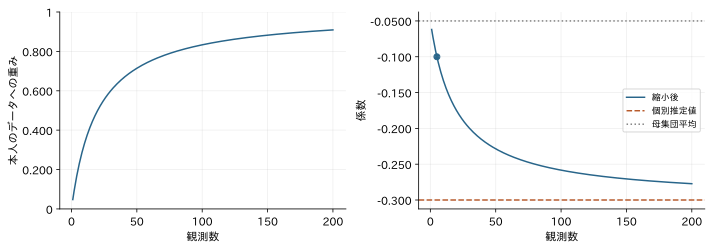

In [2]:
# 本文の補助モデル：重みと縮小後の値を数値で確認する。
mu, individual = -0.0500, -0.300
n_grid = np.arange(1, 201)
weight = n_grid / (n_grid + 20)
shrunk = weight * individual + (1 - weight) * mu
display(Math(r"w=\frac{5}{5+20}=0.200,\qquad "
             r"E[b\mid\mathbf{y}]=0.200(-0.300)+0.800(-0.0500)=-0.100"))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].plot(n_grid, weight, color=BLUE)
axes[0].set(xlabel="観測数", ylabel="本人のデータへの重み", ylim=(0, 1))
axes[1].plot(n_grid, shrunk, color=BLUE, label="縮小後")
axes[1].axhline(individual, color=ORANGE, ls="--", label="個別推定値")
axes[1].axhline(mu, color="gray", ls=":", label="母集団平均")
axes[1].scatter([5], [-0.100], color=BLUE)
axes[1].set(xlabel="観測数", ylabel="係数")
axes[1].legend(fontsize=9)
save_svg(fig, "01_shrinkage")

### MCMCと事後予測

実際の階層ロジスティック回帰では、事後分布を式だけで求めにくいためMCMCを使う。本文は、候補値を確率的に採用・棄却するMetropolis–Hastings法から説明し、実装ではNUTSを用いる。

得られたサンプルから事後平均と94% HDIを求める。HDIは密度の高い部分を優先して確率94%を含む区間で、中央94%区間とは異なる。また、各サンプルの係数で購入確率を計算し、その確率から0・1を生成すると事後予測になる。係数の不確実性と、購入結果のばらつきの両方が反映される。

<div>

$$
q_{it}^{(s)}=\sigma(a_i^{(s)}+b_i^{(s)}x_{it}),\qquad
y_{it}^{\mathrm{rep},(s)}\sim\mathrm{Bernoulli}(q_{it}^{(s)}).
$$

</div>

$s$はサンプルの番号であり、切片と傾きは同じ回の組を使う。

## 3. Pythonで個人別の価格係数を推定する

### データを準備する

本文と同じ乱数設定で、100人、各3〜29回の購入機会を生成する。母集団の価格係数の平均は$-0.800$、標準偏差は$0.300$である。1行は1回の購入機会であり、購入しなかった記録も必要となる。実測のPOSデータではない。

価格は$x=(\mathrm{price\_yen}-200)/50$に変換する。係数は50円上昇したときの対数オッズの変化を表し、冒頭の1円単位の係数とは単位が異なる。IDは文字列を残しつつ、計算用に連続整数へ変換する。

消費者数: 100、購入機会: 1675
occasion_id customer_id  price_yen  price_scaled  purchased
     O00001        C001        121         -1.58          1
     O00002        C001        113         -1.73          1
     O00003        C001        219         0.378          0
     O00004        C001        129         -1.42          1
     O00005        C001        265          1.30          0
{'C001': 0, 'C002': 1, 'C003': 2}


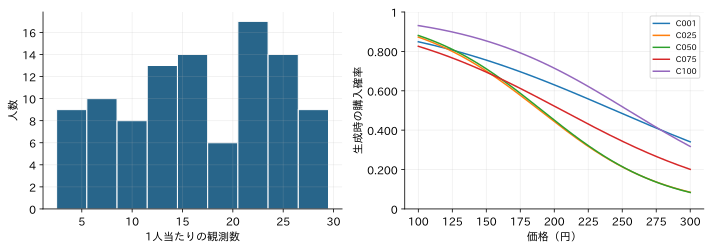

In [3]:
rng = np.random.default_rng(42)
n_customer = 100
n_obs = rng.integers(3, 30, size=n_customer)
b_true = rng.normal(-0.800, 0.300, n_customer)
a_true = rng.normal(0, 0.500, n_customer)

# 計算中は丸めず、購入と非購入の両方を記録する。
records = []
for i, n in enumerate(n_obs):
    price = rng.uniform(100, 300, n)
    scaled = (price - 200) / 50
    bought = rng.binomial(1, expit(a_true[i] + b_true[i] * scaled))
    for yen, x_value, y_value in zip(price, scaled, bought):
        records.append({
            "occasion_id": f"O{len(records) + 1:05d}",
            "customer_id": f"C{i + 1:03d}",
            "price_yen": yen, "price_scaled": x_value, "purchased": int(y_value),
        })
df = pd.DataFrame(records)
labels, idx = np.unique(df["customer_id"], return_inverse=True)
idx = idx.astype("int32")
x = df["price_scaled"].to_numpy()
y = df["purchased"].to_numpy()
print(f"消費者数: {len(labels)}、購入機会: {len(df)}")
print(df.head().to_string(index=False))
pprint(dict(zip(labels[:3].tolist(), range(3))))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(n_obs, bins=np.arange(2.5, 30.5, 3), color=BLUE, edgecolor="white")
axes[0].set(xlabel="1人当たりの観測数", ylabel="人数")
axes[0].yaxis.set_major_locator(MaxNLocator(integer=True))
price_grid = np.linspace(100, 300, 160)
x_grid = (price_grid - 200) / 50
for i in [0, 24, 49, 74, 99]:
    axes[1].plot(price_grid, expit(a_true[i] + b_true[i] * x_grid), label=labels[i])
axes[1].set(xlabel="価格（円）", ylabel="生成時の購入確率", ylim=(0, 1))
axes[1].legend(fontsize=8)
save_svg(fig, "02_data")

### 完全プール型と階層モデルを定義する

全員共通の係数を持つモデルを先に作る。階層モデルでは、$z_i\sim\mathcal N(0,1)$から$b_i=\mu_b+\tau_b z_i$を作る非中心化パラメータ化を使う。切片も同様である。`idx` が各行に対応する消費者の係数を取り出す。

In [4]:
coords = {"customer": labels.tolist(), "obs": np.arange(len(df))}
with pm.Model(coords={"obs": coords["obs"]}) as pooled_model:
    a = pm.Normal("a", mu=0, sigma=1)
    b = pm.Normal("b", mu=0, sigma=1)
    pm.Bernoulli("y_obs", logit_p=a + b * x, observed=y, dims="obs")

with pm.Model(coords=coords) as hierarchical_model:
    # 母集団 → 個人別係数 → 購入結果の順に定義する。
    mu_a = pm.Normal("mu_a", mu=0, sigma=1)
    tau_a = pm.HalfNormal("tau_a", sigma=1)
    mu_b = pm.Normal("mu_b", mu=0, sigma=1)
    tau_b = pm.HalfNormal("tau_b", sigma=1)
    z_a = pm.Normal("z_a", mu=0, sigma=1, dims="customer")
    z_b = pm.Normal("z_b", mu=0, sigma=1, dims="customer")
    a_i = pm.Deterministic("a_i", mu_a + tau_a * z_a, dims="customer")
    b_i = pm.Deterministic("b_i", mu_b + tau_b * z_b, dims="customer")
    q = pm.Deterministic("q", pm.math.sigmoid(a_i[idx] + b_i[idx] * x), dims="obs")
    pm.Bernoulli("y_obs", p=q, observed=y, dims="obs")

### 事前分布が許す購入確率を確認する

学習前に、三層のうち係数までを事前分布から生成する。帯は購入確率の中央94%区間である。価格上昇に伴い確率が増す曲線も許している。業務上の想定と合うかを確認してから学習する。

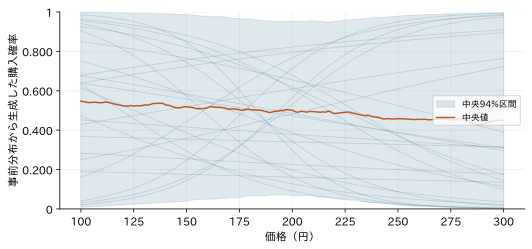

In [5]:
# 1人の消費者の係数を、母集団の事前分布も含めて繰り返し生成する。
prior_rng = np.random.default_rng(2026)
size = 500
prior_mu_a = prior_rng.normal(0, 1, size)
prior_tau_a = np.abs(prior_rng.normal(0, 1, size))
prior_mu_b = prior_rng.normal(0, 1, size)
prior_tau_b = np.abs(prior_rng.normal(0, 1, size))
prior_a = prior_rng.normal(prior_mu_a, prior_tau_a)
prior_b = prior_rng.normal(prior_mu_b, prior_tau_b)
prior_q = expit(prior_a[:, None] + prior_b[:, None] * x_grid)
low, high = np.quantile(prior_q, [0.0300, 0.970], axis=0)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.fill_between(price_grid, low, high, color=BLUE, alpha=0.150, label="中央94%区間")
ax.plot(price_grid, prior_q[:25].T, color=BLUE, alpha=0.200, lw=0.800)
ax.plot(price_grid, np.median(prior_q, axis=0), color=ORANGE, label="中央値")
ax.set(xlabel="価格（円）", ylabel="事前分布から生成した購入確率", ylim=(0, 1))
ax.legend(fontsize=9)
save_svg(fig, "03_prior")

### MCMCを実行し、学習データへの当てはまりを見る

本文と同じく4チェーン、各1000回の調整後に2000個を保存する。事後予測では同じ購入機会の結果を再生成し、価格帯別の購入率を比べる。これは学習データの再現確認であり、未知の期間の予測精度ではない。

In [6]:
with hierarchical_model:
    trace = pm.sample(
        draws=2000, tune=1000, chains=4, cores=2,
        target_accept=0.950, random_seed=42, progressbar=False,
        return_inferencedata=True,
    )

with hierarchical_model:
    predictive = pm.sample_posterior_predictive(
        trace, var_names=["y_obs"], random_seed=42, progressbar=False,
    )

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 2 jobs)


NUTS: [mu_a, tau_a, mu_b, tau_b, z_a, z_b]


Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 18 seconds.


Sampling: [y_obs]


customer_id  price_yen  purchased  購入確率の平均  再生成した購入率
       C001        121          1    0.783     0.783
       C025        295          0    0.180     0.184
       C050        172          0    0.551     0.554
       C075        261          0    0.182     0.183
       C100        300          0    0.210     0.220


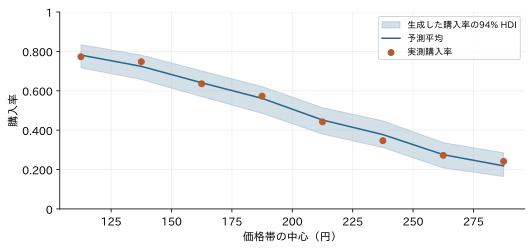

In [7]:
def samples(result, variable, dimension, group="posterior"):
    """チェーンと反復をまとめ、行をサンプル、列を対象にそろえる。"""
    return (result[group][variable].stack(sample=("chain", "draw"))
            .transpose("sample", dimension).values)


def hdi_columns(values):
    return np.array([az.hdi(column, prob=0.940) for column in values.T])


q_draws = samples(trace, "q", "obs")
y_rep = samples(predictive, "y_obs", "obs", "posterior_predictive")
selected = [np.flatnonzero(idx == i)[0] for i in [0, 24, 49, 74, 99]]
prediction_table = df.iloc[selected][["customer_id", "price_yen", "purchased"]].copy()
prediction_table["購入確率の平均"] = q_draws[:, selected].mean(axis=0)
prediction_table["再生成した購入率"] = y_rep[:, selected].mean(axis=0)
print(prediction_table.to_string(index=False))

# 同じ価格帯の購入機会をまとめ、購入率の事後予測分布を作る。
edges = np.linspace(100, 300, 9)
bins = np.digitize(df["price_yen"], edges[1:-1])
centers = (edges[:-1] + edges[1:]) / 2
observed = np.array([y[bins == b].mean() for b in range(8)])
rep_rates = np.column_stack([y_rep[:, bins == b].mean(axis=1) for b in range(8)])
interval = hdi_columns(rep_rates)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.fill_between(centers, interval[:, 0], interval[:, 1], color=BLUE, alpha=0.200,
                label="生成した購入率の94% HDI")
ax.plot(centers, rep_rates.mean(axis=0), color=BLUE, label="予測平均")
ax.scatter(centers, observed, color=ORANGE, label="実測購入率", zorder=3)
ax.set(xlabel="価格帯の中心（円）", ylabel="購入率", ylim=(0, 1))
ax.legend(fontsize=9)
save_svg(fig, "04_posterior_predictive")

### 計算が安定しているかを確認する

$\hat R$はチェーン間の一致、ESSは実質的なサンプルの情報量を表す。補助変数も含めて確認し、発散数、探索効率の指標BFMI、トレースも併せて見る。母集団平均のトレースだけで、全変数の安定性を判断しない。

{'最大R_hat': '1.00',
 '最小ESS_bulk': '2.36e+03',
 '最小ESS_tail': '3.07e+03',
 '発散数': 0}
array([0.702, 0.704, 0.691, 0.733])
数値診断の目安を満たす: True
{'94% HDI': ['0.000392', '0.340'], '価格係数の母集団標準偏差': '0.190'}


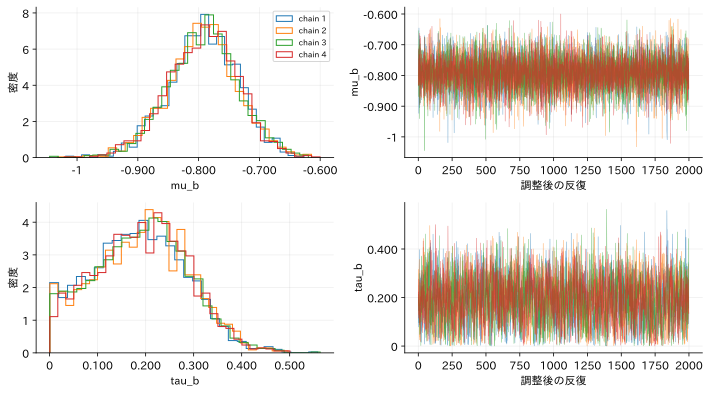

In [8]:
diagnostic_vars = ["mu_a", "tau_a", "mu_b", "tau_b", "z_a", "z_b", "a_i", "b_i"]
diagnostics = az.summary(trace, var_names=diagnostic_vars, kind="diagnostics", round_to="none")
max_rhat = float(diagnostics["r_hat"].max())
min_bulk = float(diagnostics["ess_bulk"].min())
min_tail = float(diagnostics["ess_tail"].min())
divergences = int(trace.sample_stats["diverging"].sum().item())
energy = trace.sample_stats["energy"].values
bfmi = np.mean(np.diff(energy, axis=1) ** 2, axis=1) / np.var(energy, axis=1)
pprint({"最大R_hat": f"{max_rhat:#.3g}", "最小ESS_bulk": f"{min_bulk:#.3g}",
        "最小ESS_tail": f"{min_tail:#.3g}", "発散数": divergences})
pprint(bfmi)
# 判定には表示用に丸める前の値を使う。
stable = max_rhat < 1.01 and min_bulk > 400 and min_tail > 400 and divergences == 0 and bfmi.min() > 0.300
print(f"数値診断の目安を満たす: {stable}")
tau_draws = trace.posterior["tau_b"].values.ravel()
tau_low, tau_high = az.hdi(tau_draws, prob=0.940)
pprint({"価格係数の母集団標準偏差": fmt3(tau_draws.mean()),
        "94% HDI": [fmt3(tau_low), fmt3(tau_high)]})

fig, axes = plt.subplots(2, 2, figsize=(10, 5.6))
for row, variable in enumerate(["mu_b", "tau_b"]):
    chain_values = trace.posterior[variable].values
    for chain, values in enumerate(chain_values):
        axes[row, 0].hist(values, bins=30, density=True, histtype="step", label=f"chain {chain + 1}")
        axes[row, 1].plot(values, lw=0.500, alpha=0.650)
    axes[row, 0].set(xlabel=variable, ylabel="密度")
    axes[row, 1].set(xlabel="調整後の反復", ylabel=variable)
axes[0, 0].legend(fontsize=8)
save_svg(fig, "05_trace")

### 個人別の推定値を施策の検討に使う

この実行では発散は0で、数値診断の目安を満たした。ただし、母集団の標準偏差には広い推定区間が残る。計算の安定と推定の確かさは別である。

事後平均と94% HDIを出力する。真値との比較は模擬データだから可能である。観測が多くても、価格の変化が乏しければ区間は狭くなりにくい。HDI上限が$-0.500$未満という条件は、検証候補を抽出する例にすぎない。実際の基準は利益と費用を踏まえて決める。

消費者ID  観測数   事後平均  HDI下限  HDI上限  検証候補
 C017   16 -0.926  -1.40 -0.571  True
 C062   23 -0.905  -1.33 -0.527  True
 C015   22 -0.903  -1.33 -0.530  True
 C038   25 -0.899  -1.36 -0.569  True
 C059   23 -0.896  -1.34 -0.542  True
 C013   22 -0.894  -1.31 -0.551  True
 C028   25 -0.892  -1.31 -0.547  True
 C094   13 -0.888  -1.36 -0.538  True
例示基準を満たす人数: 19 / 100


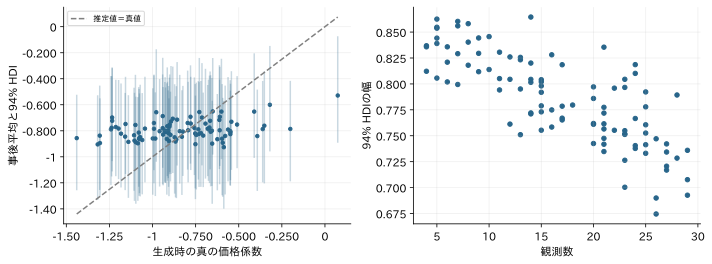

In [9]:
b_draws = samples(trace, "b_i", "customer")
b_mean = b_draws.mean(axis=0)
b_hdi = hdi_columns(b_draws)
candidate = b_hdi[:, 1] < -0.500
customer_table = pd.DataFrame({
    "消費者ID": labels, "観測数": n_obs, "事後平均": b_mean,
    "HDI下限": b_hdi[:, 0], "HDI上限": b_hdi[:, 1], "検証候補": candidate,
})
print(customer_table.sort_values("事後平均").head(8).to_string(index=False))
print(f"例示基準を満たす人数: {int(candidate.sum())} / {n_customer}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].vlines(b_true, b_hdi[:, 0], b_hdi[:, 1], color=BLUE, alpha=0.250)
axes[0].scatter(b_true, b_mean, color=BLUE, s=12)
limits = [min(b_true.min(), b_hdi.min()), max(b_true.max(), b_hdi.max())]
axes[0].plot(limits, limits, "--", color="gray", label="推定値＝真値")
axes[0].set(xlabel="生成時の真の価格係数", ylabel="事後平均と94% HDI")
axes[0].legend(fontsize=8)
axes[1].scatter(n_obs, b_hdi[:, 1] - b_hdi[:, 0], color=BLUE, s=20)
axes[1].set(xlabel="観測数", ylabel="94% HDIの幅")
save_svg(fig, "06_individual")

### 母集団の推定値を比較する

最後に完全プール型の共通係数と、階層モデルの母集団平均を並べる。両者は推定する対象が異なり、共通係数が個人別係数の単純平均になるとは限らない。この図だけで予測精度の優劣は判断できない。

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 2 jobs)


NUTS: [a, b]


Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 3 seconds.


   ess_bulk  ess_tail  r_hat  mcse_mean  mcse_sd
a  5.14e+03  4.49e+03   1.00   0.000732 0.000598
b  5.35e+03  4.65e+03   1.00   0.000677 0.000589
完全プール型の発散数: 0
       推定対象     平均  HDI下限  HDI上限
完全プール型の共通係数 -0.749 -0.840 -0.654
階層モデルの母集団平均 -0.793 -0.900 -0.683


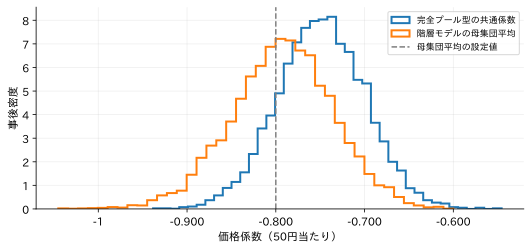

In [10]:
with pooled_model:
    pooled_trace = pm.sample(
        draws=2000, tune=1000, chains=4, cores=2,
        target_accept=0.950, random_seed=42, progressbar=False,
        return_inferencedata=True,
    )

# 比較モデルについても数値診断を出力する。
pooled_diagnostics = az.summary(pooled_trace, var_names=["a", "b"], kind="diagnostics", round_to="none")
print(pooled_diagnostics.to_string())
print(f"完全プール型の発散数: {int(pooled_trace.sample_stats['diverging'].sum().item())}")
fig, ax = plt.subplots(figsize=(7.5, 3.6))
rows = []
for name, draws in [
    ("完全プール型の共通係数", pooled_trace.posterior["b"].values.ravel()),
    ("階層モデルの母集団平均", trace.posterior["mu_b"].values.ravel()),
]:
    low, high = az.hdi(draws, prob=0.940)
    rows.append({"推定対象": name, "平均": draws.mean(), "HDI下限": low, "HDI上限": high})
    ax.hist(draws, bins=40, density=True, histtype="step", lw=2, label=name)
ax.axvline(-0.800, color="gray", ls="--", label="母集団平均の設定値")
ax.set(xlabel="価格係数（50円当たり）", ylabel="事後密度")
ax.legend(fontsize=9)
print(pd.DataFrame(rows).to_string(index=False))
save_svg(fig, "07_comparison")

## 結論

この記事では、階層ベイズモデルで全体の情報を共有し、消費者ごとの価格係数と不確実性を推定する方法を紹介した。

今回の事後平均は共通係数が$-0.749$、母集団平均が$-0.793$となった。一方、個人別の区間には幅があり、例示基準を満たす候補は100人中19人であった。

縮小推定は、履歴が少ない人の推定を安定させる。ただし、情報不足がなくなるわけではない。私は、係数の順位だけでなく、推定区間も見て検証対象を決める方が実務で使いやすいと考える。観測データから得た価格との関連は、値引きの因果効果を保証しない。候補者を無作為に分けた検証で、購入率に加えて増分利益を確認する必要がある。

[『マーケティングサイエンスの理論と実践』](https://gihyo.jp/book/2026/978-4-297-16025-8)では、こうした課題、理論、実装、施策の判断を順に扱う。第6章の詳しい説明と[サポートページ](https://github.com/gihyo-book/marketing_science_book)の実装も、モデルを自分のデータに適用する際の参考になる。